# E-Commerce Sales & Customer Analytics
Exploratory data analysis on 540,000+ transaction records from the UCI Online Retail dataset using PostgreSQL and Python (Pandas, Matplotlib, Seaborn).

## 1. Environment Setup & Database Connection
We connect to our local PostgreSQL database (`online_retail_analytics`) using SQLAlchemy and configure standard visualization settings.

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine, text

# Set clean visualization styling
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.figsize"] = (9.5, 4.5)

# Connect to local PostgreSQL database
engine = create_engine("postgresql://localhost:5432/online_retail_analytics")
print("Connected to database: online_retail_analytics")

Connected to database: online_retail_analytics


## 2. Data Cleaning & Validation
The raw dataset contains cancellations (invoices prefixed with 'C'), inventory write-offs with negative or zero quantities, and invalid prices.

First, we audit how many bad records exist in the raw table. Then, we create a clean view (`clean_retail`) so that all our downstream sales queries automatically reference verified transactions.

In [15]:
# Check raw data health: cancellations, negative quantities, and zero/negative prices
audit_query = """
SELECT 
    COUNT(*) AS total_raw_rows,
    COUNT(CASE WHEN invoice_no LIKE 'C%' THEN 1 END) AS cancelled_invoices,
    COUNT(CASE WHEN quantity <= 0 THEN 1 END) AS non_positive_quantity,
    COUNT(CASE WHEN unit_price <= 0 THEN 1 END) AS non_positive_price,
    COUNT(CASE 
        WHEN invoice_no NOT LIKE 'C%' 
         AND quantity > 0 
         AND unit_price > 0 
        THEN 1 
    END) AS valid_clean_rows
FROM raw_retail;
"""
df_audit = pd.read_sql(text(audit_query), engine)
df_audit

,total_raw_rows,cancelled_invoices,non_positive_quantity,non_positive_price,valid_clean_rows
0,541909,9288,10624,2521,530100


In [16]:
# Create clean view in PostgreSQL
create_view_sql = """
DROP VIEW IF EXISTS clean_retail;

CREATE VIEW clean_retail AS
SELECT 
    invoice_no,
    stock_code,
    description,
    quantity,
    invoice_date,
    unit_price,
    ROUND((quantity * unit_price), 2) AS total_revenue,
    customer_id,
    country
FROM raw_retail
WHERE invoice_no NOT LIKE 'C%'
  AND quantity > 0
  AND unit_price > 0;
"""
with engine.begin() as conn:
    conn.execute(text(create_view_sql))

# Verify that the clean view is ready
clean_count = pd.read_sql(text("SELECT COUNT(*) AS clean_rows FROM clean_retail;"), engine)
clean_count

,clean_rows
0,530100


## 3. Geographic Sales Breakdown
We compare sales in the home market (UK) against international markets, and look at the top 5 countries driving international revenue.

In [17]:
# Domestic (UK) vs International revenue comparison
split_query = """
SELECT 
    CASE 
        WHEN country = 'United Kingdom' THEN 'United Kingdom' 
        ELSE 'International (Non-UK)' 
    END AS market_segment,
    COUNT(DISTINCT invoice_no) AS total_orders,
    ROUND(SUM(total_revenue), 2) AS total_revenue,
    ROUND(100.0 * SUM(total_revenue) / SUM(SUM(total_revenue)) OVER (), 2) AS pct_of_total
FROM clean_retail
GROUP BY 1
ORDER BY total_revenue DESC;
"""
df_split = pd.read_sql(text(split_query), engine)
df_split

,market_segment,total_orders,total_revenue,pct_of_total
0,United Kingdom,18019,9025222.08,84.61
1,International (Non-UK),1941,1641462.46,15.39


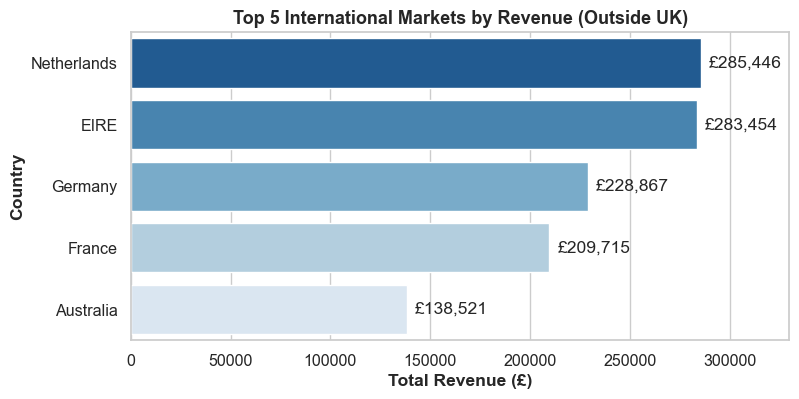

,country,total_orders,total_revenue,avg_order_value,intl_revenue_share_pct
0,Netherlands,94,285446.34,3036.66,17.39
1,EIRE,288,283453.96,984.22,17.27
2,Germany,457,228867.14,500.80,13.94
3,France,392,209715.11,534.99,12.78
4,Australia,57,138521.31,2430.20,8.44


In [18]:
# Top 5 international markets outside the UK
intl_query = """
SELECT 
    country,
    COUNT(DISTINCT invoice_no) AS total_orders,
    ROUND(SUM(total_revenue), 2) AS total_revenue,
    ROUND(SUM(total_revenue) / COUNT(DISTINCT invoice_no), 2) AS avg_order_value,
    ROUND(100.0 * SUM(total_revenue) / SUM(SUM(total_revenue)) OVER (), 2) AS intl_revenue_share_pct
FROM clean_retail
WHERE country != 'United Kingdom'
GROUP BY country
ORDER BY total_revenue DESC
LIMIT 5;
"""
df_intl = pd.read_sql(text(intl_query), engine)

# Visualize top international markets
plt.figure(figsize=(8.5, 4))
ax = sns.barplot(data=df_intl, y="country", x="total_revenue", hue="country", palette="Blues_r", legend=False)
plt.title("Top 5 International Markets by Revenue (Outside UK)", fontsize=13, weight="bold")
plt.xlabel("Total Revenue (£)", weight="bold")
plt.ylabel("Country", weight="bold")
for p in ax.patches:
    ax.annotate(f"£{p.get_width():,.0f}", (p.get_width() + 4000, p.get_y() + p.get_height() / 2), va="center")
plt.xlim(0, 330000)
plt.show()

df_intl

## 4. Sales Trends & Peak Demand Windows
Next, we examine monthly revenue to identify seasonal spikes, and hourly orders to see what time of day customers place the most orders.

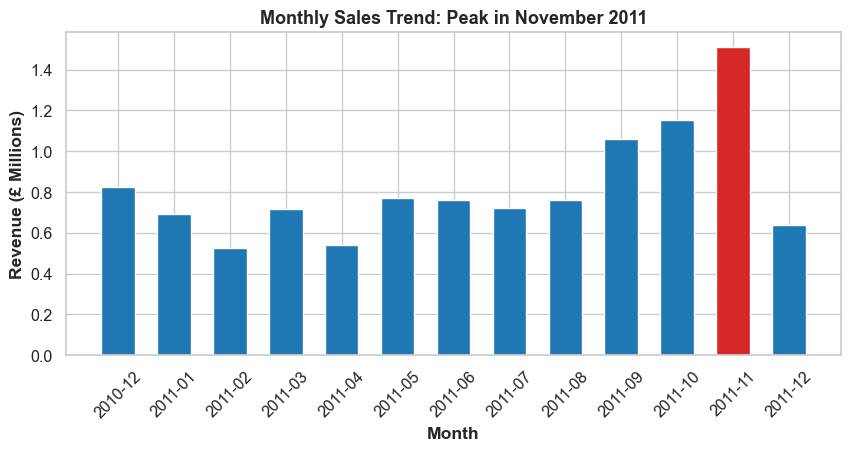

,sales_month,total_orders,monthly_revenue,mom_growth_pct
0,2010-12,1559,823746.14,NaN
1,2011-01,1086,691364.56,-16.07
2,2011-02,1100,523631.89,-24.26
3,2011-03,1454,717639.36,37.05
4,2011-04,1246,537808.62,-25.06
5,2011-05,1681,770536.02,43.27
6,2011-06,1533,761739.90,-1.14
7,2011-07,1475,719221.19,-5.58
8,2011-08,1361,759138.38,5.55
9,2011-09,1837,1058590.17,39.45


In [19]:
# Monthly revenue and month-over-month growth using LAG()
monthly_query = """
WITH monthly_sales AS (
    SELECT 
        TO_CHAR(invoice_date, 'YYYY-MM') AS sales_month,
        COUNT(DISTINCT invoice_no) AS total_orders,
        ROUND(SUM(total_revenue), 2) AS monthly_revenue
    FROM clean_retail
    GROUP BY 1
)
SELECT 
    sales_month,
    total_orders,
    monthly_revenue,
    ROUND(100.0 * (monthly_revenue - LAG(monthly_revenue, 1) OVER (ORDER BY sales_month)) 
          / LAG(monthly_revenue, 1) OVER (ORDER BY sales_month), 2) AS mom_growth_pct
FROM monthly_sales
ORDER BY sales_month;
"""
df_monthly = pd.read_sql(text(monthly_query), engine)

# Plot monthly sales trend
plt.figure(figsize=(10, 4.2))
bar_colors = ["#d62728" if m == "2011-11" else "#1f77b4" for m in df_monthly["sales_month"]]
plt.bar(df_monthly["sales_month"], df_monthly["monthly_revenue"] / 1e6, color=bar_colors, width=0.6)
plt.title("Monthly Sales Trend: Peak in November 2011", fontsize=13, weight="bold")
plt.xlabel("Month", weight="bold")
plt.ylabel("Revenue (£ Millions)", weight="bold")
plt.xticks(rotation=45)
plt.show()

df_monthly

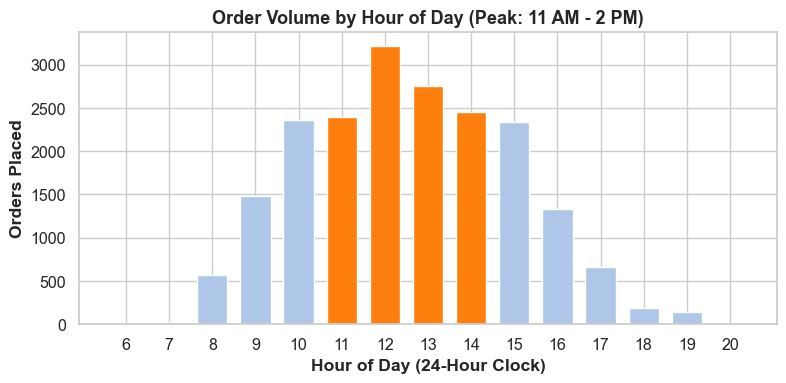

In [20]:
# Order volume by hour of day
hourly_query = """
SELECT 
    EXTRACT(HOUR FROM invoice_date)::INTEGER AS order_hour,
    COUNT(DISTINCT invoice_no) AS total_orders
FROM clean_retail
GROUP BY 1
ORDER BY order_hour;
"""
df_hourly = pd.read_sql(text(hourly_query), engine)

plt.figure(figsize=(9, 3.8))
peak_hours = [11, 12, 13, 14]
colors = ["#ff7f0e" if h in peak_hours else "#aec7e8" for h in df_hourly["order_hour"]]
plt.bar(df_hourly["order_hour"], df_hourly["total_orders"], color=colors, width=0.7)
plt.title("Order Volume by Hour of Day (Peak: 11 AM - 2 PM)", fontsize=13, weight="bold")
plt.xlabel("Hour of Day (24-Hour Clock)", weight="bold")
plt.ylabel("Orders Placed", weight="bold")
plt.xticks(df_hourly["order_hour"])
plt.show()

## 5. Customer Retention & RFM Segmentation
We group registered customers (excluding anonymous guest checkouts) by:
* **Recency:** Days since last order
* **Frequency:** Number of unique purchases
* **Monetary:** Total lifetime spend

In [21]:
# Top 10 highest-spending customers using DENSE_RANK()
top_spenders_query = """
WITH customer_orders AS (
    SELECT 
        customer_id,
        invoice_no,
        invoice_date::date AS order_date,
        total_revenue
    FROM clean_retail
    WHERE customer_id IS NOT NULL
),
rfm_raw AS (
    SELECT 
        customer_id,
        (SELECT MAX(order_date) FROM customer_orders) - MAX(order_date) AS recency_days,
        COUNT(DISTINCT invoice_no) AS frequency,
        ROUND(SUM(total_revenue), 2) AS monetary_total
    FROM customer_orders
    GROUP BY customer_id
)
SELECT 
    DENSE_RANK() OVER (ORDER BY monetary_total DESC) AS spend_rank,
    customer_id,
    recency_days,
    frequency,
    monetary_total,
    ROUND(monetary_total / frequency, 2) AS avg_order_value
FROM rfm_raw
ORDER BY spend_rank
LIMIT 10;
"""
df_spenders = pd.read_sql(text(top_spenders_query), engine)
df_spenders

,spend_rank,customer_id,recency_days,frequency,monetary_total,avg_order_value
0,1,14646,1,73,280206.02,3838.44
1,2,18102,0,60,259657.30,4327.62
2,3,17450,8,46,194550.79,4229.37
3,4,16446,0,2,168472.50,84236.25
4,5,14911,1,201,143825.06,715.55
5,6,12415,24,21,124914.53,5948.31
6,7,14156,9,55,117379.63,2134.18
7,8,17511,2,31,91062.38,2937.50
8,9,16029,38,63,81024.84,1286.11
9,10,12346,325,1,77183.60,77183.60


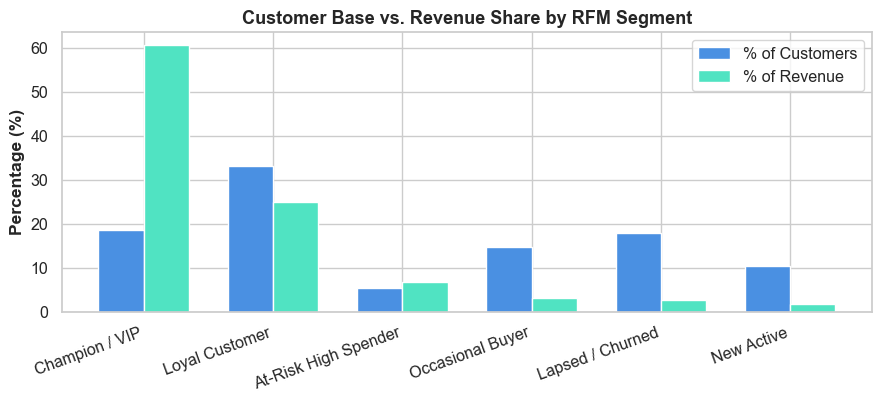

,customer_segment,total_customers,customer_pct,segment_revenue,revenue_pct
0,Champion / VIP,802,18.5,5400582.67,60.6
1,Loyal Customer,1441,33.2,2216381.59,24.9
2,At-Risk High Spender,232,5.3,609547.67,6.8
3,Occasional Buyer,641,14.8,280504.67,3.1
4,Lapsed / Churned,776,17.9,243489.22,2.7
5,New Active,446,10.3,160902.08,1.8


In [22]:
# Customer segmentation breakdown
rfm_segment_query = """
WITH customer_orders AS (
    SELECT customer_id, invoice_no, invoice_date::date AS order_date, total_revenue
    FROM clean_retail WHERE customer_id IS NOT NULL
),
rfm_base AS (
    SELECT 
        customer_id,
        (SELECT MAX(order_date) FROM customer_orders) - MAX(order_date) AS recency_days,
        COUNT(DISTINCT invoice_no) AS frequency,
        ROUND(SUM(total_revenue), 2) AS monetary_total
    FROM customer_orders
    GROUP BY customer_id
),
rfm_segments AS (
    SELECT 
        CASE 
            WHEN recency_days <= 30 AND frequency >= 5 THEN 'Champion / VIP'
            WHEN recency_days <= 90 AND frequency >= 2 THEN 'Loyal Customer'
            WHEN recency_days <= 60 AND frequency = 1  THEN 'New Active'
            WHEN recency_days > 90 AND monetary_total >= 1000 THEN 'At-Risk High Spender'
            WHEN recency_days > 180 THEN 'Lapsed / Churned'
            ELSE 'Occasional Buyer'
        END AS customer_segment,
        monetary_total
    FROM rfm_base
)
SELECT 
    customer_segment,
    COUNT(*) AS total_customers,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS customer_pct,
    ROUND(SUM(monetary_total), 2) AS segment_revenue,
    ROUND(100.0 * SUM(monetary_total) / SUM(SUM(monetary_total)) OVER (), 1) AS revenue_pct
FROM rfm_segments
GROUP BY customer_segment
ORDER BY segment_revenue DESC;
"""
df_rfm = pd.read_sql(text(rfm_segment_query), engine)

# Visualize Customer Base % vs Revenue Share %
fig, ax = plt.subplots(figsize=(9, 4.2))
indices = range(len(df_rfm))
width = 0.35
ax.bar([i - width/2 for i in indices], df_rfm['customer_pct'], width, label='% of Customers', color='#4a90e2')
ax.bar([i + width/2 for i in indices], df_rfm['revenue_pct'], width, label='% of Revenue', color='#50e3c2')
ax.set_title("Customer Base vs. Revenue Share by RFM Segment", fontsize=13, weight="bold")
ax.set_ylabel("Percentage (%)", weight="bold")
ax.set_xticks(indices)
ax.set_xticklabels(df_rfm['customer_segment'], rotation=20, ha='right')
ax.legend()
plt.tight_layout()
plt.show()

df_rfm

## 6. Product Returns & Cancellation Diagnostics
We query the raw, uncleaned dataset to calculate which products suffer from the highest cancellation rates.

In [23]:
# Highest cancellation rates for products with at least 20 orders
cancellation_query = """
WITH product_orders AS (
    SELECT 
        stock_code,
        MAX(CASE WHEN description IS NOT NULL AND description != '' THEN description END) AS product_name,
        COUNT(DISTINCT invoice_no) AS total_orders,
        COUNT(DISTINCT CASE WHEN invoice_no LIKE 'C%' THEN invoice_no END) AS cancelled_orders
    FROM raw_retail
    GROUP BY stock_code
)
SELECT 
    stock_code,
    COALESCE(product_name, 'No Description') AS product_description,
    total_orders,
    cancelled_orders,
    ROUND(100.0 * cancelled_orders / total_orders, 2) AS cancellation_rate_pct
FROM product_orders
WHERE total_orders >= 20
ORDER BY cancellation_rate_pct DESC
LIMIT 12;
"""
df_cancels = pd.read_sql(text(cancellation_query), engine)
df_cancels

,stock_code,product_description,total_orders,cancelled_orders,cancellation_rate_pct
0,D,Discount,65,65,100.00
1,AMAZONFEE,AMAZON FEE,34,32,94.12
2,BANK CHARGES,Bank Charges,36,25,69.44
3,M,Manual,517,223,43.13
4,23064,Crushed,34,10,29.41
5,85232B,SET OF 3 BABUSHKA STACKING TINS,21,6,28.57
6,22656,VINTAGE BLUE KITCHEN CABINET,27,6,22.22
7,23462,ROCOCO WALL MIRROR WHITE,59,12,20.34
8,22461,SAVOY ART DECO CLOCK,67,13,19.40
9,85159B,"WHITE TEA,COFFEE,SUGAR JARS",72,13,18.06


## 7. Summary of Key Insights
* **Data Cleaning:** 11,809 invalid records (2.18%) were filtered out, leaving 530,100 clean transactions representing £10.67M in revenue.
* **Geographic Patterns:** The UK accounts for 84.6% of sales. Outside the UK, the Netherlands (£3,036 AOV) and Australia (£2,430 AOV) exhibit wholesale/B2B purchasing patterns.
* **Demand Timing:** November 2011 is the peak revenue month (£1.51M) due to holiday demand. Daily orders heavily concentrate between 11:00 AM and 2:00 PM (54% of daily volume).
* **Customer Retention:** The top 18.5% of customers (Champions/VIPs) generate 60.6% of revenue. 232 At-Risk High Spenders represent an immediate win-back opportunity (~£90K).
* **Product Returns:** Cancellations cluster around fragile decor (chandeliers, mirrors) and heavy furniture, pointing to in-transit parcel damages.